In [18]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [19]:
df = pd.read_csv("../data/processed_traffic.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.isnull().sum())

Dataset shape: (840, 8)
   reading_id road_id sensor_id            timestamp  vehicle_count  \
0           1    R001      S001  2026-08-20 00:00:00             11   
1           2    R002      S002  2026-08-20 00:00:00             21   
2           3    R003      S003  2026-08-20 00:00:00             42   
3           4    R004      S004  2026-08-20 00:00:00             50   
4           5    R005      S005  2026-08-20 00:00:00             14   

   avg_speed  density congestion  
0      20.22    77.28       High  
1      54.22     7.07        Low  
2      29.74    69.90       High  
3      23.77    68.77       High  
4      33.00    84.14       High  
reading_id       0
road_id          0
sensor_id        0
timestamp        0
vehicle_count    0
avg_speed        0
density          0
congestion       0
dtype: int64


In [20]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Create time-based features
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

# Peak-hour feature
df["is_peak_hour"] = (
    ((df["hour"] >= 7) & (df["hour"] <= 10)) |
    ((df["hour"] >= 17) & (df["hour"] <= 20))
).astype(int)

# Encode road IDs
road_mapping = {
    road_id: index
    for index, road_id in enumerate(sorted(df["road_id"].unique()))
}

df["road_id_encoded"] = df["road_id"].map(road_mapping)

print("Road mapping:", road_mapping)
print(df.head())

Road mapping: {'R001': 0, 'R002': 1, 'R003': 2, 'R004': 3, 'R005': 4}
   reading_id road_id sensor_id  timestamp  vehicle_count  avg_speed  density  \
0           1    R001      S001 2026-08-20             11      20.22    77.28   
1           2    R002      S002 2026-08-20             21      54.22     7.07   
2           3    R003      S003 2026-08-20             42      29.74    69.90   
3           4    R004      S004 2026-08-20             50      23.77    68.77   
4           5    R005      S005 2026-08-20             14      33.00    84.14   

  congestion  hour  day_of_week  is_peak_hour  road_id_encoded  
0       High     0            3             0                0  
1        Low     0            3             0                1  
2       High     0            3             0                2  
3       High     0            3             0                3  
4       High     0            3             0                4  


In [21]:
features = [
    "road_id_encoded",
    "vehicle_count",
    "avg_speed",
    "density",
    "hour",
    "day_of_week",
    "is_peak_hour"
]

target = "congestion"

X = df[features]
y = df[target]

print("Features:", features)
print("Target:", target)
print("\nClasses:")
print(y.unique())

Features: ['road_id_encoded', 'vehicle_count', 'avg_speed', 'density', 'hour', 'day_of_week', 'is_peak_hour']
Target: congestion

Classes:
['High' 'Low' 'Medium']


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 672
Testing samples: 168


In [23]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [24]:
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Test Accuracy:", accuracy)

Random Forest Test Accuracy: 0.9940476190476191


In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        81
         Low       1.00      0.96      0.98        24
      Medium       0.98      1.00      0.99        63

    accuracy                           0.99       168
   macro avg       0.99      0.99      0.99       168
weighted avg       0.99      0.99      0.99       168



In [26]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[81  0  0]
 [ 0 23  1]
 [ 0  0 63]]


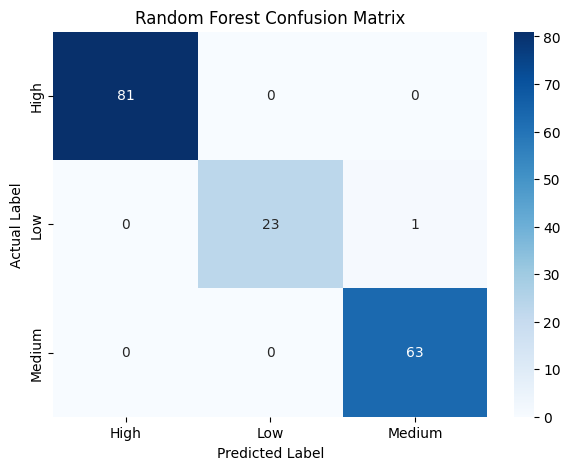

In [27]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [41]:
import joblib
from pathlib import Path

model_path = Path("Sowjanya-ai-ml/models/congestion_model.pkl")

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)

Model saved successfully!
Path: Sowjanya-ai-ml\models\congestion_model.pkl
